**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación · CICESE  
M.C. Joan Manuel Raygoza Romero

# ICD 23 · Autoencoders con MNIST

Sesión 23 del curso. Diapositivas: [icd-22-ae.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-23-ae.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-23-ae.ipynb)

Una imagen de MNIST tiene **784 intensidades**. Vamos a usar la misma colección de dígitos para estudiar tres objetivos distintos.

| Experimento | Entrada | Objetivo | Evidencia |
|---|---|---|---|
| Reducción dimensional | Imagen limpia | Reconstruir la imagen desde dos coordenadas | Mapas 2D, reconstrucciones, MSE y un clasificador *k*-NN |
| Denoising | Imagen degradada | Recuperar la imagen limpia | MSE, PSNR, curvas por severidad y ejemplos difíciles |
| Generación | Un latente del prior y, en CVAE, una clase | Crear un dígito sintético | Grillas, distribuciones de clases y fidelidad a la condición |

Ejecuta las celdas en orden. El notebook usa **TensorFlow/Keras y scikit-learn**. Funciona en Jupyter o Colab con TensorFlow ≥ 2.16. En un entorno vacío, instala `tensorflow scikit-learn matplotlib pandas` con `%pip install` y reinicia el kernel. MNIST se descarga en la primera ejecución. Los bloques de CNN constituyen la mayor parte del tiempo de ejecución en CPU.

## 1. Preparación y protocolo

Reservamos la prueba oficial de MNIST. Dividimos las 60 000 imágenes oficiales de entrenamiento de forma estratificada en **54 000 de entrenamiento** y **6 000 de validación**. Normalizamos los píxeles a $[0,1]$. Cada bloque usa subconjuntos estratificados y reproducibles para que la práctica sea manejable.

Las clases sirven para estratificar y colorear los puntos. También se usan para entrenar el **CVAE**, su evaluador y el clasificador *k*-NN. Tanto el AE de compresión como el DAE y el VAE se ajustan a partir de imágenes.

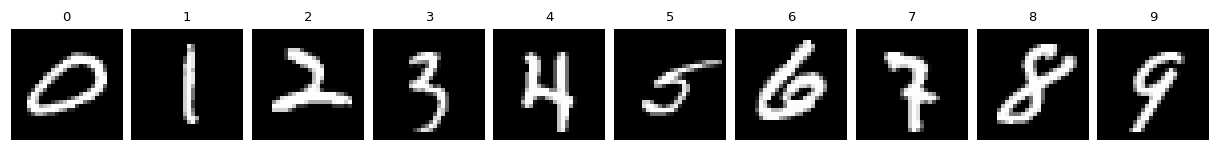

Entrenamiento 54,000 | Validación 6,000 | Prueba 10,000


In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from matplotlib.colors import BoundaryNorm
from sklearn.decomposition import KernelPCA, PCA
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits
from tensorflow import keras
from tensorflow.keras import layers

SEMILLA = 23
LOTE = 128
keras.utils.set_random_seed(SEMILLA)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 105, "font.size": 10})

(x_oficial, y_oficial), (x_test, y_test) = keras.datasets.mnist.load_data()
ix_train, ix_val = train_test_split(
    np.arange(len(y_oficial)), test_size=6000, stratify=y_oficial,
    random_state=SEMILLA,
)
x_oficial = x_oficial[..., None].astype("float32") / 255.0
x_test = x_test[..., None].astype("float32") / 255.0
x_train, y_train = x_oficial[ix_train], y_oficial[ix_train]
x_val, y_val = x_oficial[ix_val], y_oficial[ix_val]
del x_oficial, y_oficial

def muestra_estratificada(x, y, n, semilla):
    indices, _ = train_test_split(
        np.arange(len(y)), train_size=n, stratify=y, random_state=semilla,
    )
    return x[indices], y[indices]

def mostrar_imagen(ax, imagen, titulo=""):
    ax.imshow(np.squeeze(imagen), cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo, fontsize=9)
    ax.set_axis_off()

def mse_por_imagen(real, estimacion):
    return np.mean((real - estimacion) ** 2, axis=tuple(range(1, real.ndim)))

def preparar_datos(x, objetivo=None, *, mezclar=False, semilla=SEMILLA):
    elementos = x if objetivo is None else (x, objetivo)
    datos = tf.data.Dataset.from_tensor_slices(elementos)
    if mezclar:
        n = len(next(iter(x.values()))) if isinstance(x, dict) else len(x)
        datos = datos.shuffle(min(n, 6000), seed=semilla)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

fig, axs = plt.subplots(1, 10, figsize=(11.5, 1.6), layout="constrained")
for digito, ax in enumerate(axs):
    imagen = x_train[np.flatnonzero(y_train == digito)[0]]
    mostrar_imagen(ax, imagen, str(digito))
plt.show()
print(f"Entrenamiento {len(x_train):,} | Validación {len(x_val):,} | Prueba {len(x_test):,}")

## 2. Compresión a dos dimensiones

**PCA** proyecta las imágenes en dos direcciones lineales y reconstruye por proyección inversa. **Kernel PCA con RBF** calcula una representación no lineal mediante similitudes entre ejemplos.

Todos ven las mismas **3 500 imágenes** de entrenamiento, escogen su configuración con validación y se comparan sobre las mismas **2 000 imágenes de prueba**. Kernel PCA usa una matriz de similitudes. Para esta práctica limitamos $n$ y probamos tres valores de $gamma$. En el AE comparamos una capa oculta por lado con tres capas por lado. Reportamos el tamaño de ambos para que la comparación se pueda interpretar.

In [2]:
x_a_train, y_a_train = muestra_estratificada(x_train, y_train, 3500, SEMILLA)
x_a_val, _ = muestra_estratificada(x_val, y_val, 1500, SEMILLA)
x_a_test, y_a_test = muestra_estratificada(x_test, y_test, 2000, SEMILLA)

a_train = x_a_train.reshape(-1, 784)
a_val = x_a_val.reshape(-1, 784)
a_test = x_a_test.reshape(-1, 784)

rng = np.random.default_rng(SEMILLA)
pares = rng.integers(0, len(a_train), size=(1200, 2))
distancias = np.sum((a_train[pares[:, 0]] - a_train[pares[:, 1]]) ** 2, axis=1)
gamma_base = 1 / np.median(distancias[distancias > 0])

pca = PCA(n_components=2, random_state=SEMILLA).fit(a_train)
gamma_tabla = []
kpca = None
mejor_mse = np.inf
for factor in (0.5, 1.0, 2.0):
    gamma = float(factor * gamma_base)
    candidato = KernelPCA(
        n_components=2, kernel="rbf", gamma=gamma, alpha=0.02,
        fit_inverse_transform=True, random_state=SEMILLA,
    ).fit(a_train)
    reconstruccion = np.clip(candidato.inverse_transform(candidato.transform(a_val)), 0, 1)
    error = float(mse_por_imagen(a_val, reconstruccion).mean())
    gamma_tabla.append({"Factor": factor, "Gamma": gamma, "MSE validación": error})
    if error < mejor_mse:
        kpca, mejor_mse = candidato, error

display(pd.DataFrame(gamma_tabla).round(6))

,Factor,Gamma,MSE validación
0,0.5,0.004758,0.055915
1,1.0,0.009517,0.055892
2,2.0,0.019034,0.056192


,Arquitectura,Parámetros,MSE validación
1,AE profundo,485266,0.04410
0,AE base,202258,0.04802


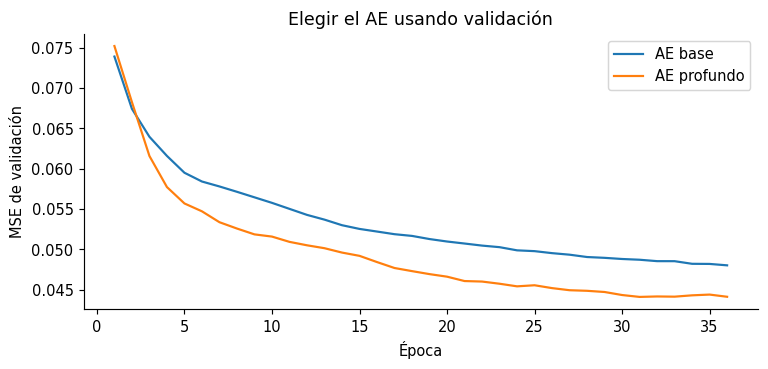

In [3]:
def crear_ae_denso(anchos):
    entrada = keras.Input((784,), name="imagen")
    h = entrada
    for ancho in anchos:
        h = layers.Dense(ancho, activation="relu")(h)
    codigo = layers.Dense(2, name="codigo_2d")(h)
    encoder = keras.Model(entrada, codigo, name="encoder")

    z = keras.Input((2,), name="latente")
    h = z
    for ancho in reversed(anchos):
        h = layers.Dense(ancho, activation="relu")(h)
    salida = layers.Dense(784, activation="sigmoid")(h)
    decoder = keras.Model(z, salida, name="decoder")

    ae = keras.Model(entrada, decoder(encoder(entrada)))
    ae.compile(optimizer=keras.optimizers.Adam(0.002), loss="mse")
    return ae, encoder, decoder

def parada_temprana(paciencia=4):
    return keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=paciencia, restore_best_weights=True,
        min_delta=0.00003,
    )

datos_a_val = preparar_datos(a_val, a_val)
aes, historias_a, resumen_a = {}, {}, []
for nombre, anchos in {"AE base": (128,), "AE profundo": (256, 128, 64)}.items():
    keras.utils.set_random_seed(SEMILLA)
    ae, encoder, decoder = crear_ae_denso(anchos)
    datos_a_train = preparar_datos(a_train, a_train, mezclar=True)
    historia = ae.fit(datos_a_train, validation_data=datos_a_val, epochs=36,
                      callbacks=[parada_temprana(6)], shuffle=False, verbose=0).history
    aes[nombre] = (ae, encoder, decoder)
    historias_a[nombre] = historia
    resumen_a.append({"Arquitectura": nombre, "Parámetros": ae.count_params(),
                      "MSE validación": ae.evaluate(datos_a_val, verbose=0)})

resultados_a = pd.DataFrame(resumen_a).sort_values("MSE validación")
ae_elegido = resultados_a.iloc[0]["Arquitectura"]
ae, encoder_2d, decoder_2d = aes[ae_elegido]
display(resultados_a.round(5))

fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
for nombre, historia in historias_a.items():
    ax.plot(np.arange(1, len(historia["val_loss"]) + 1), historia["val_loss"], label=nombre)
ax.set(xlabel="Época", ylabel="MSE de validación", title="Elegir el AE usando validación")
ax.legend()
plt.show()

,Método,MSE de reconstrucción,Exactitud k-NN en 2D
0,PCA,0.0554,0.4330
1,Kernel PCA,0.0553,0.3815
2,AE profundo,0.0435,0.6450


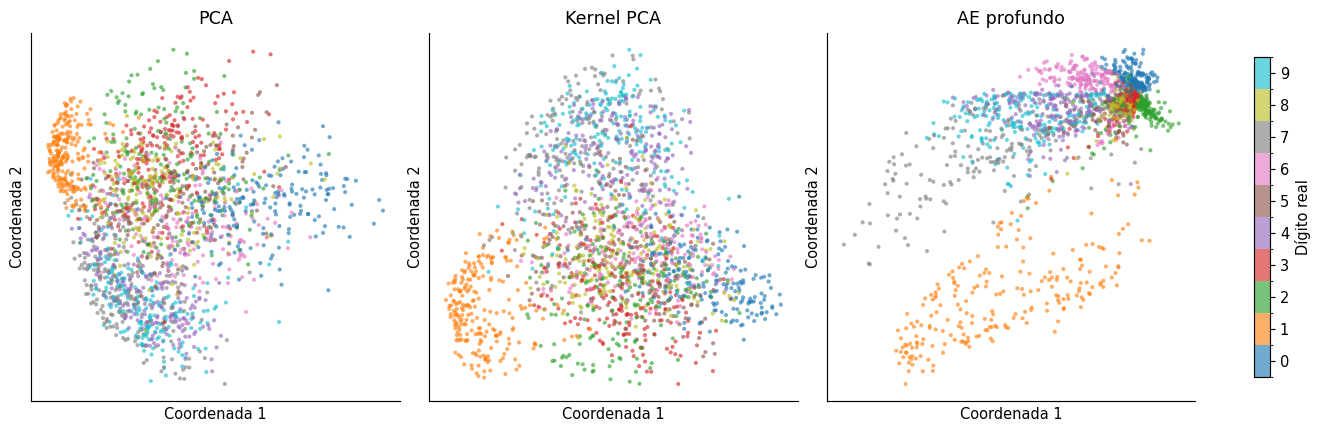

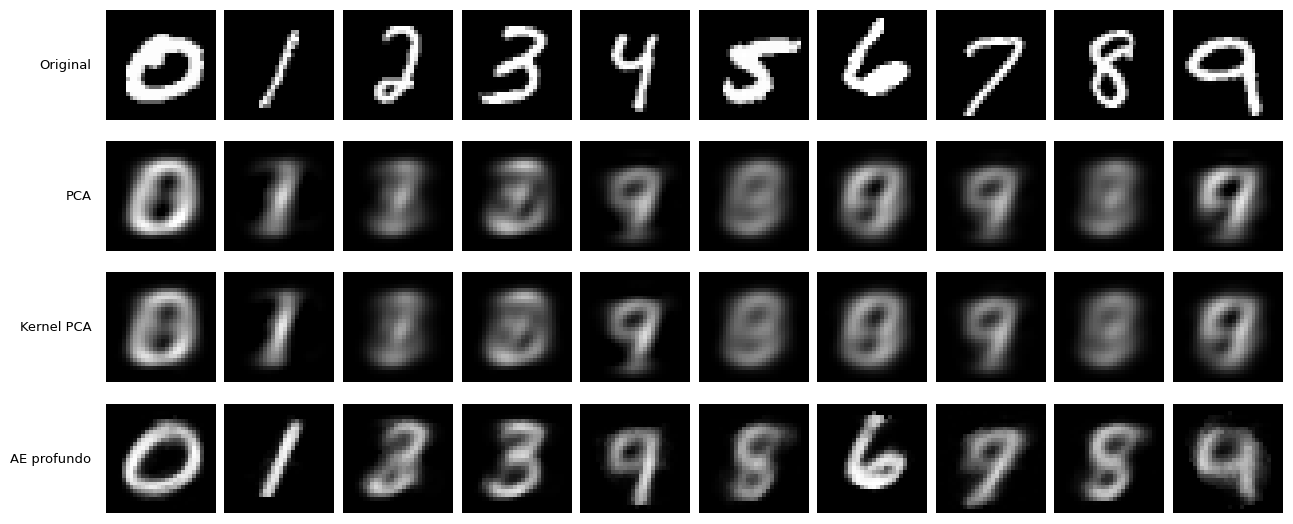

In [4]:
def predecir(modelo, entradas):
    return modelo.predict(preparar_datos(entradas), verbose=0)

z_train_pca, z_test_pca = pca.transform(a_train), pca.transform(a_test)
z_train_kpca, z_test_kpca = kpca.transform(a_train), kpca.transform(a_test)
rec_pca = np.clip(pca.inverse_transform(z_test_pca), 0, 1)
rec_kpca = np.clip(kpca.inverse_transform(z_test_kpca), 0, 1)

z_train_ae = predecir(encoder_2d, a_train)
z_test_ae = predecir(encoder_2d, a_test)
rec_ae = predecir(decoder_2d, z_test_ae)

comparacion_2d = {
    "PCA": (z_train_pca, z_test_pca, rec_pca),
    "Kernel PCA": (z_train_kpca, z_test_kpca, rec_kpca),
    ae_elegido: (z_train_ae, z_test_ae, rec_ae),
}
filas = []
for nombre, (z_tr, z_te, rec) in comparacion_2d.items():
    clasificador = KNeighborsClassifier(n_neighbors=10).fit(z_tr, y_a_train)
    filas.append({"Método": nombre,
                  "MSE de reconstrucción": mse_por_imagen(a_test, rec).mean(),
                  "Exactitud k-NN en 2D": clasificador.score(z_te, y_a_test)})

display(pd.DataFrame(filas).round(4))

fig, axs = plt.subplots(1, 3, figsize=(12.5, 4.0), layout="constrained")
norma_digitos = BoundaryNorm(np.arange(-0.5, 10.5, 1), 10)
for ax, (nombre, (_, z_te, _)) in zip(axs, comparacion_2d.items()):
    puntos = ax.scatter(*z_te.T, c=y_a_test, cmap="tab10", norm=norma_digitos,
                       s=8, alpha=0.63, linewidths=0)
    ax.set(title=nombre, xlabel="Coordenada 1", ylabel="Coordenada 2")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(puntos, ax=axs, ticks=np.arange(10), label="Dígito real", shrink=0.87)
plt.show()

ejemplos_2d = [np.flatnonzero(y_a_test == k)[0] for k in range(10)]
fig, axs = plt.subplots(4, 10, figsize=(12.2, 5.0), layout="constrained")
imagenes_2d = {"Original": a_test, **{k: v[2] for k, v in comparacion_2d.items()}}
for fila, (nombre, imagenes) in enumerate(imagenes_2d.items()):
    for ax, i in zip(axs[fila], ejemplos_2d):
        mostrar_imagen(ax, imagenes[i].reshape(28, 28))
    axs[fila, 0].text(-0.13, 0.5, nombre, transform=axs[fila, 0].transAxes,
                     ha="right", va="center", fontsize=9)
plt.show()

El MSE mide fidelidad en píxeles. El *k*-NN es una forma supervisada que pregunta si, en el espacio de dos dimensiones, ejemplos cercanos suelen tener la misma etiqueta. No interviene en el aprendizaje. Los ejes de cada mapa tienen escalas distintas y su orientación es arbitraria. Para calcular el MSE, llevamos todas las reconstrucciones al intervalo $[0,1]$.

¿Cuál de los métodos conserva detalles del trazo en las reconstrucciones? ¿Elegirías el mismo método para visualizar vecindarios y para reconstruir imágenes?

## 3. Denoising con un autoencoder convolucional

Construimos pares $(\tilde{x},x)$ degradando artificialmente cada imagen. La entrada $\tilde{x}$ contiene ruido y el objetivo $x$ es el dígito limpio. Comparamos dos CNN de **idéntica arquitectura**. Una ve ruido gaussiano de dos intensidades. La otra ve una mezcla de ruido gaussiano, sal y pimienta y oclusión. Las dos se entrenan durante siete épocas con el mismo conjunto de imágenes limpias y se monitorean en el mismo conjunto mixto de validación.

La CNN conserva un mapa de $7\times7$ en su cuello de botella. El encoder reduce resolución con convoluciones de *stride* 2 y el decoder la recupera con `UpSampling2D` seguido de convoluciones. Las capas pequeñas y los filtros compartidos mantienen el coste bajo. La última convolución produce logits. Una sigmoide los convierte en intensidades de $[0,1]$. Entrenamos con entropía cruzada binaria sobre los logits para que el cálculo sea numéricamente estable.

In [5]:
def corromper(imagenes, tipo, nivel, semilla):
    # Devuelve las imágenes degradadas y un mapa booleano de la zona expuesta.
    rng = np.random.default_rng(semilla)
    degradadas = imagenes.copy()
    if tipo == "Gaussiano":
        ruido = rng.standard_normal(imagenes.shape, dtype=np.float32) * nivel
        np.clip(degradadas + ruido, 0, 1, out=degradadas)
        zona = np.ones_like(degradadas, dtype=bool)
    elif tipo == "Sal y pimienta":
        u = rng.random(imagenes.shape, dtype=np.float32)
        zona = (u < nivel / 2) | (u >= 1 - nivel / 2)
        degradadas[u < nivel / 2] = 0
        degradadas[u >= 1 - nivel / 2] = 1
    elif tipo == "Oclusión":
        lado = int(nivel)
        filas = rng.integers(0, 29 - lado, size=(len(imagenes), 1, 1, 1))
        columnas = rng.integers(0, 29 - lado, size=(len(imagenes), 1, 1, 1))
        i = np.arange(28)[None, :, None, None]
        j = np.arange(28)[None, None, :, None]
        zona = (i >= filas) & (i < filas + lado) & (j >= columnas) & (j < columnas + lado)
        degradadas[zona] = 0
    else:
        raise ValueError(f"Corrupción desconocida: {tipo}")
    return degradadas, zona

GAUSSIANO = [("Gaussiano", 0.25), ("Gaussiano", 0.50)]
MEZCLA = GAUSSIANO + [("Sal y pimienta", 0.15), ("Sal y pimienta", 0.35),
                     ("Oclusión", 8), ("Oclusión", 13)]

def degradar_lote(imagenes, escenarios, semilla):
    rng = np.random.default_rng(semilla)
    partes = np.array_split(rng.permutation(len(imagenes)), len(escenarios))
    resultado = np.empty_like(imagenes)
    for indices, (tipo, nivel) in zip(partes, escenarios):
        resultado[indices], _ = corromper(imagenes[indices], tipo, nivel,
                                          int(rng.integers(2**31)))
    return resultado

def crear_dae():
    entrada = keras.Input((28, 28, 1))
    h = layers.Conv2D(12, 3, padding="same", activation="relu")(entrada)
    h = layers.Conv2D(16, 3, strides=2, padding="same", activation="relu")(h)
    z = layers.Conv2D(24, 3, strides=2, padding="same", activation="relu",
                      name="codigo_espacial")(h)
    h = layers.UpSampling2D(2)(z)
    h = layers.Conv2D(16, 3, padding="same", activation="relu")(h)
    h = layers.UpSampling2D(2)(h)
    h = layers.Conv2D(12, 3, padding="same", activation="relu")(h)
    logits = layers.Conv2D(1, 3, padding="same",
                           bias_initializer=keras.initializers.Constant(-1.6))(h)
    dae = keras.Model(entrada, logits)
    dae.compile(optimizer=keras.optimizers.Adam(0.001),
                loss=keras.losses.BinaryCrossentropy(from_logits=True))
    return dae

Parámetros entrenables por DAE: 10,665


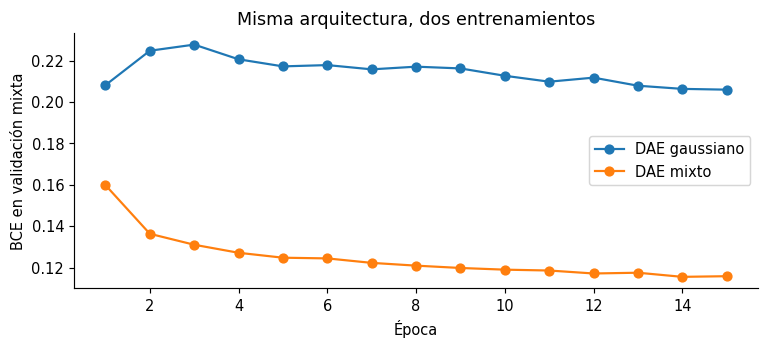

In [6]:
x_d_train, _ = muestra_estratificada(x_train, y_train, 16000, SEMILLA + 1)
x_d_val, _ = muestra_estratificada(x_val, y_val, 1800, SEMILLA + 1)
x_d_test, y_d_test = muestra_estratificada(x_test, y_test, 1500, SEMILLA + 1)

# Las dos redes se monitorean con el mismo conjunto mixto de validación.
x_d_val_ruido = degradar_lote(x_d_val, MEZCLA, SEMILLA + 20)
datos_d_val = preparar_datos(x_d_val_ruido, x_d_val)
daes, historias_d = {}, {}
for nombre, escenarios in {"DAE gaussiano": GAUSSIANO, "DAE mixto": MEZCLA}.items():
    keras.utils.set_random_seed(SEMILLA)
    x_d_ruido = degradar_lote(x_d_train, escenarios, SEMILLA + 21)
    datos_d_train = preparar_datos(x_d_ruido, x_d_train, mezclar=True)
    dae = crear_dae()
    historias_d[nombre] = dae.fit(
        datos_d_train, validation_data=datos_d_val, epochs=15,
        shuffle=False, verbose=0,
    ).history
    daes[nombre] = dae
    del x_d_ruido, datos_d_train

print(f"Parámetros entrenables por DAE: {dae.count_params():,}")
fig, ax = plt.subplots(figsize=(7.2, 3.2), layout="constrained")
for nombre, historia in historias_d.items():
    ax.plot(np.arange(1, len(historia["val_loss"]) + 1), historia["val_loss"],
            marker="o", label=nombre)
ax.set(xlabel="Época", ylabel="BCE en validación mixta", title="Misma arquitectura, dos entrenamientos")
ax.legend()
plt.show()

### 3.1 Evaluación por tipo y severidad

Evaluamos las dos redes y la **entrada degradada** sobre los mismos píxeles. Esto permite detectar si pasar por el DAE mejora la imagen. El **MSE** promedia el error cuadrático en todos los píxeles. El **PSNR** usa una escala en decibeles, $\mathrm{PSNR}=10\log_{10}(1/\mathrm{MSE})$ para intensidades en $[0,1]$. Aquí calculamos un PSNR agregado por escenario a partir del MSE medio. Así, los parches que caen enteramente sobre fondo negro y dejan la imagen intacta tienen un peso proporcionado. Reportamos también el MSE en la **zona expuesta** a la corrupción.

En la prueba extrema usamos $\sigma=0.90$ de ruido gaussiano, probabilidad $0.75$ de sal y pimienta y una oclusión de $22\times22$. La posición de la oclusión se genera para cada imagen. El valor cero rellena el cuadrado y la CNN recibe solo la imagen modificada.

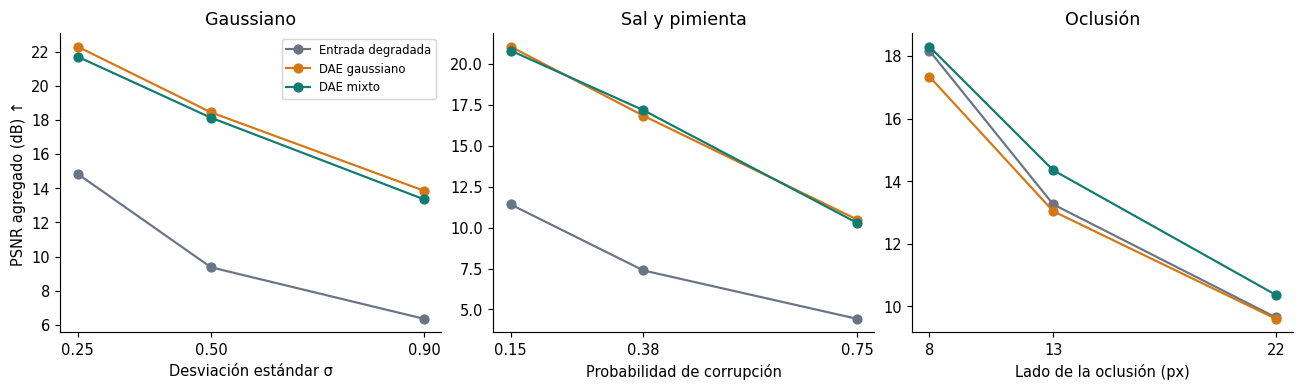

,Tipo,Nivel,Modelo,MSE,PSNR (dB),MSE zona expuesta
0,Gaussiano,0.90,Entrada degradada,0.2315,6.3545,0.2315
1,Gaussiano,0.90,DAE gaussiano,0.0412,13.8510,0.0412
2,Gaussiano,0.90,DAE mixto,0.0463,13.3488,0.0463
3,Sal y pimienta,0.75,Entrada degradada,0.3611,4.4233,0.4817
4,Sal y pimienta,0.75,DAE gaussiano,0.0893,10.4938,0.1019
5,Sal y pimienta,0.75,DAE mixto,0.0936,10.2886,0.1061
6,Oclusión,22.00,Entrada degradada,0.1084,9.6496,0.1756
7,Oclusión,22.00,DAE gaussiano,0.1095,9.6054,0.1752
8,Oclusión,22.00,DAE mixto,0.0918,10.3700,0.1472


In [7]:
PRUEBAS_RUIDO = {"Gaussiano": (0.25, 0.50, 0.90),
                 "Sal y pimienta": (0.15, 0.38, 0.75),
                 "Oclusión": (8, 13, 22)}
COLORES_DAE = {"Entrada degradada": "#697586", "DAE gaussiano": "#d47815",
               "DAE mixto": "#117c72"}

metricas_d, ejemplos_d = [], {}
for j, (tipo, niveles) in enumerate(PRUEBAS_RUIDO.items()):
    for k, nivel in enumerate(niveles):
        x_ruido, zona = corromper(x_d_test, tipo, nivel, SEMILLA + 40 + 3*j + k)
        salidas = {"Entrada degradada": x_ruido}
        salidas.update({nombre: tf.sigmoid(predecir(red, x_ruido)).numpy()
                        for nombre, red in daes.items()})
        for nombre, salida in salidas.items():
            err = (x_d_test - salida)**2
            mse_i = err.mean(axis=(1, 2, 3))
            metricas_d.append({"Tipo": tipo, "Nivel": nivel, "Modelo": nombre,
                               "MSE": mse_i.mean(),
                               "PSNR (dB)": -10 * np.log10(max(mse_i.mean(), 1e-12)),
                               "MSE zona expuesta": err[zona].mean()})
        if k in (0, 2):
            ejemplos_d[tipo, nivel] = salidas

tabla_d = pd.DataFrame(metricas_d)
fig, axs = plt.subplots(1, 3, figsize=(12.3, 3.6), layout="constrained")
ejes_ruido = {"Gaussiano": "Desviación estándar σ", "Sal y pimienta": "Probabilidad de corrupción",
              "Oclusión": "Lado de la oclusión (px)"}
for ax, (tipo, niveles) in zip(axs, PRUEBAS_RUIDO.items()):
    for nombre, color in COLORES_DAE.items():
        datos = tabla_d[(tabla_d["Tipo"] == tipo) & (tabla_d["Modelo"] == nombre)]
        ax.plot(datos["Nivel"], datos["PSNR (dB)"], marker="o", label=nombre, color=color)
    ax.set(title=tipo, xlabel=ejes_ruido[tipo], xticks=niveles)
axs[0].set_ylabel("PSNR agregado (dB) ↑")
axs[0].legend(fontsize=8)
plt.show()

es_extremo = [(tipo, nivel) in {(t, ns[-1]) for t, ns in PRUEBAS_RUIDO.items()}
              for tipo, nivel in zip(tabla_d["Tipo"], tabla_d["Nivel"])]
display(tabla_d.loc[es_extremo].round(4).reset_index(drop=True))

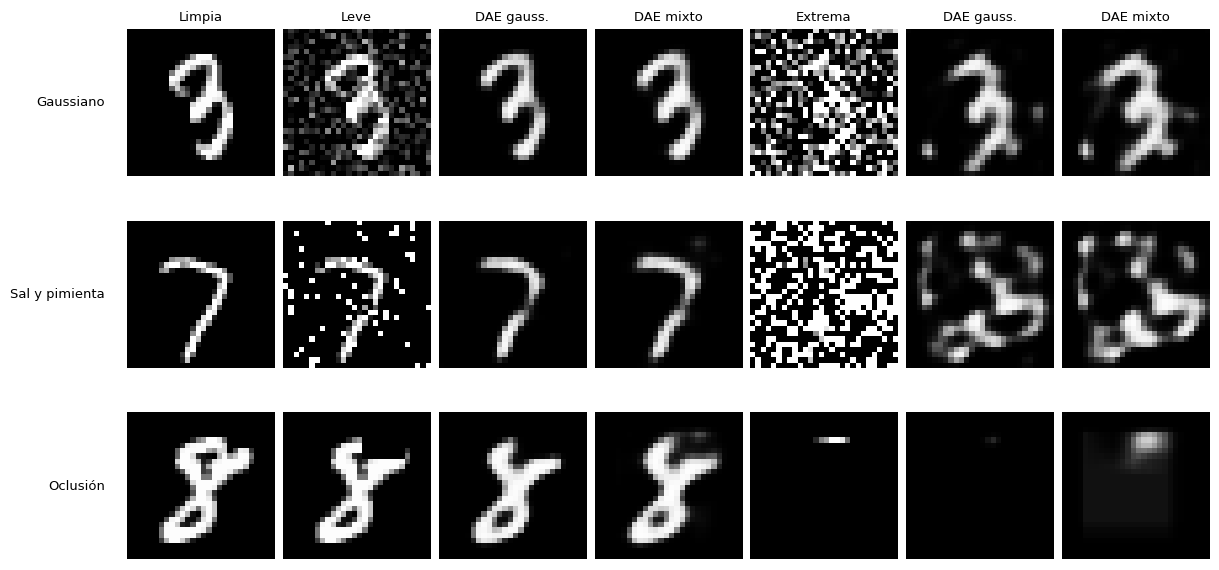

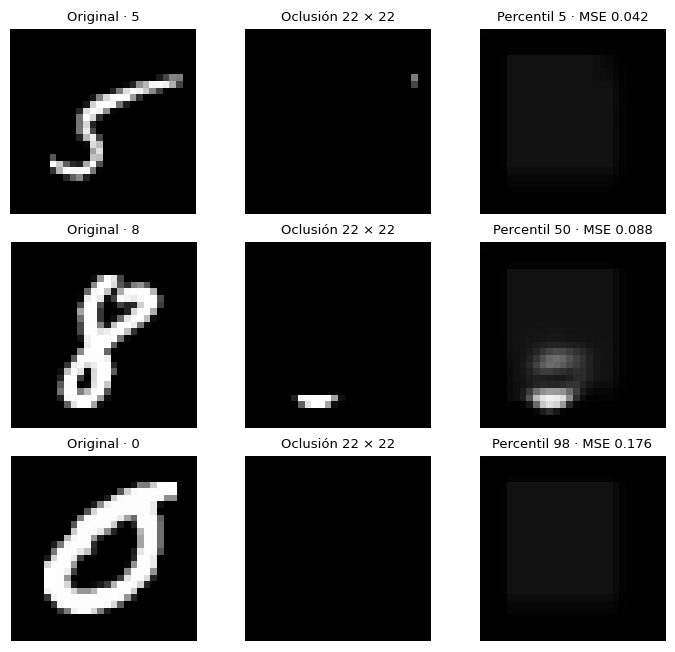

In [8]:
fig, axs = plt.subplots(3, 7, figsize=(11.5, 5.5), layout="constrained")
for fila, (tipo, niveles) in enumerate(PRUEBAS_RUIDO.items()):
    i = np.flatnonzero(y_d_test == (3, 7, 8)[fila])[4]
    bajo = ejemplos_d[tipo, niveles[0]]
    alto = ejemplos_d[tipo, niveles[-1]]
    imagenes = [x_d_test[i], *(x[i] for x in bajo.values()), *(x[i] for x in alto.values())]
    titulos = ["Limpia", "Leve", "DAE gauss.", "DAE mixto", "Extrema", "DAE gauss.", "DAE mixto"]
    for ax, imagen, titulo in zip(axs[fila], imagenes, titulos):
        mostrar_imagen(ax, imagen, titulo if fila == 0 else "")
    axs[fila, 0].text(-0.15, 0.5, tipo, transform=axs[fila, 0].transAxes,
                     va="center", ha="right", fontsize=9)
plt.show()

# Caso difícil reproducible. Ordenamos por error del DAE mixto en oclusión extrema.
oclusion = ejemplos_d["Oclusión", 22]
errores = mse_por_imagen(x_d_test, oclusion["DAE mixto"])
orden = np.argsort(errores)
indices = orden[[int(0.05*len(orden)), len(orden)//2, int(0.98*len(orden))]]
fig, axs = plt.subplots(3, 3, figsize=(6.7, 6.1), layout="constrained")
for fila, (percentil, i) in enumerate(zip((5, 50, 98), indices)):
    mostrar_imagen(axs[fila, 0], x_d_test[i], f"Original · {y_d_test[i]}")
    mostrar_imagen(axs[fila, 1], oclusion["Entrada degradada"][i], "Oclusión 22 × 22")
    mostrar_imagen(axs[fila, 2], oclusion["DAE mixto"][i],
                   f"Percentil {percentil} · MSE {errores[i]:.3f}")
plt.show()

La línea de la entrada mide cuánto error introdujo cada corrupción. Si el DAE supera su PSNR, la reconstrucción se acerca en promedio al original en píxeles. Una oclusión extrema puede borrar casi todo el trazo. En ese caso, una salida plausible puede corresponder al dígito equivocado o borrar detalles que sí sobrevivieron.

## 4. VAE y CVAE para generar dígitos

En un **VAE**, el encoder predice $\mu$ y $\log\sigma^2$ para una distribución latente aproximada $q_\phi(z\mid x)$. Muestreamos con la **reparametrización** $z=\mu+\sigma\odot\epsilon$, con $\epsilon\sim\mathcal N(0,I)$. Así el gradiente de reconstrucción puede llegar a $\mu$ y $\sigma$. Para generar, se toma $z\sim\mathcal N(0,I)$ y se ejecuta el decoder.

Minimizamos por imagen una entropía cruzada sumada sobre los 784 píxeles y el término KL sumado sobre las dimensiones latentes.

$$
\mathcal L(x)=
\operatorname{BCE}_{\text{píxeles}}(x,\hat{x})
+ \beta\,D_{\mathrm{KL}}\!\left(q_\phi(z\mid x)\,\Vert\,\mathcal N(0,I)\right).
$$

Usamos las intensidades en $[0,1]$ como objetivos suaves de la BCE. Durante los primeros pasos por los datos subimos $\beta$ gradualmente hasta $2$ para que el encoder y el decoder puedan comenzar a aprender la reconstrucción. Aproximamos el promedio sobre $z$ con una muestra por imagen.

El **CVAE** añade una condición $c$, el dígito solicitado en formato *one-hot*, al encoder $q_\phi(z\mid x,c)$ y al decoder $p_\theta(x\mid z,c)$. Usamos el **mismo prior** $p(z\mid c)=\mathcal N(0,I)$ para todas las clases. Cuando generamos, elegimos $c$, muestreamos $z$ y usamos directamente el decoder. Así podemos variar la clase o explorar distintos trazos dentro de una clase.

### 4.1 Arquitectura y entrenamiento

Ambas redes usan el mismo tronco convolucional. Reducimos la resolución en dos pasos, usamos un latente de **ocho dimensiones** para guardar más información del trazo y ampliamos los mapas del decoder con convoluciones transpuestas. En el CVAE concatenamos las diez entradas de condición en la parte densa de ambos bloques. Multiplicamos el vector de clase por cuatro justo antes de concatenarlo en el decoder para darle mayor peso en las primeras actualizaciones. En estas comparaciones mantenemos los mismos datos, dimensiones latentes, épocas y optimizador. El tamaño del modelo crece ligeramente para acomodar la condición.

In [9]:
LATENTE = 8
EPOCAS_V = 50
ESCALA_CONDICION = 4.0

def crear_bloques_variacionales(condicional):
    imagen = keras.Input((28, 28, 1), name="imagen")
    h = layers.Conv2D(16, 3, strides=2, padding="same", activation="relu")(imagen)
    h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(h)
    h = layers.Flatten()(h)
    entrada_encoder = {"imagen": imagen}
    if condicional:
        c_enc = keras.Input((10,), name="clase")
        h = layers.Concatenate()([h, c_enc])
        entrada_encoder["clase"] = c_enc
    h = layers.Dense(128, activation="relu")(h)
    mu = layers.Dense(LATENTE, name="mu")(h)
    log_var = layers.Dense(LATENTE, name="log_var")(h)
    encoder = keras.Model(entrada_encoder, [mu, log_var], name="encoder")

    z = keras.Input((LATENTE,), name="z")
    entrada_decoder = {"z": z}
    h = z
    if condicional:
        c_dec = keras.Input((10,), name="clase")
        condicion = layers.Rescaling(ESCALA_CONDICION)(c_dec)
        h = layers.Concatenate()([z, condicion])
        entrada_decoder["clase"] = c_dec
    h = layers.Dense(7*7*32, activation="relu")(h)
    h = layers.Reshape((7, 7, 32))(h)
    h = layers.Conv2DTranspose(24, 4, strides=2, padding="same", activation="relu")(h)
    h = layers.Conv2DTranspose(16, 4, strides=2, padding="same", activation="relu")(h)
    logits = layers.Conv2D(1, 3, padding="same", name="logits")(h)
    decoder = keras.Model(entrada_decoder, logits, name="decoder")
    return encoder, decoder

class ModeloVariacional(keras.Model):
    def __init__(self, condicional):
        super().__init__()
        self.condicional = condicional
        self.encoder, self.decoder = crear_bloques_variacionales(condicional)
        self.beta = self.add_weight(name="beta", shape=(), initializer="ones", trainable=False)
        self.generador = keras.random.SeedGenerator(SEMILLA + 80)
        self.loss_media = keras.metrics.Mean(name="loss")
        self.bce_media = keras.metrics.Mean(name="BCE")
        self.kl_media = keras.metrics.Mean(name="KL")

    @property
    def metrics(self):
        return [self.loss_media, self.bce_media, self.kl_media]

    def entrada_decoder(self, z, entradas):
        return {"z": z, "clase": entradas["clase"]} if self.condicional else {"z": z}

    def call(self, entradas, training=False):
        mu, _ = self.encoder(entradas, training=training)
        logits = self.decoder(self.entrada_decoder(mu, entradas), training=training)
        return tf.sigmoid(logits)

    def terminos(self, entradas, training):
        imagen = entradas["imagen"]
        mu, log_var = self.encoder(entradas, training=training)
        log_var = tf.clip_by_value(log_var, -12.0, 8.0)
        epsilon = keras.random.normal(tf.shape(mu), seed=self.generador)
        z = mu + tf.exp(0.5 * log_var) * epsilon
        logits = self.decoder(self.entrada_decoder(z, entradas), training=training)
        bce = tf.reduce_sum(
            tf.nn.sigmoid_cross_entropy_with_logits(labels=imagen, logits=logits),
            axis=(1, 2, 3),
        )
        kl = -0.5 * tf.reduce_sum(1 + log_var - tf.square(mu) - tf.exp(log_var), axis=1)
        return bce + self.beta * kl, bce, kl

    def train_step(self, datos):
        entradas, _, _ = keras.utils.unpack_x_y_sample_weight(datos)
        with tf.GradientTape() as cinta:
            terminos = self.terminos(entradas, training=True)
            perdida = tf.reduce_mean(terminos[0])
        gradientes = cinta.gradient(perdida, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradientes, self.trainable_variables))
        return self.registrar(terminos)

    def test_step(self, datos):
        entradas, _, _ = keras.utils.unpack_x_y_sample_weight(datos)
        return self.registrar(self.terminos(entradas, training=False))

    def registrar(self, terminos):
        for metrica, valores in zip(self.metrics, terminos):
            metrica.update_state(valores)
        return {metrica.name: metrica.result() for metrica in self.metrics}

class SubirBeta(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.model.beta.assign(min(2, 0.25 * (epoch + 1)))

def entradas_variacionales(x, y=None):
    datos = {"imagen": x}
    if y is not None:
        datos["clase"] = np.eye(10, dtype=np.float32)[y]
    return datos

,Modelo,Parámetros entrenables,BCE de validación,KL de validación
0,VAE,240425,94.921,13.549
1,CVAE,257385,92.724,10.558


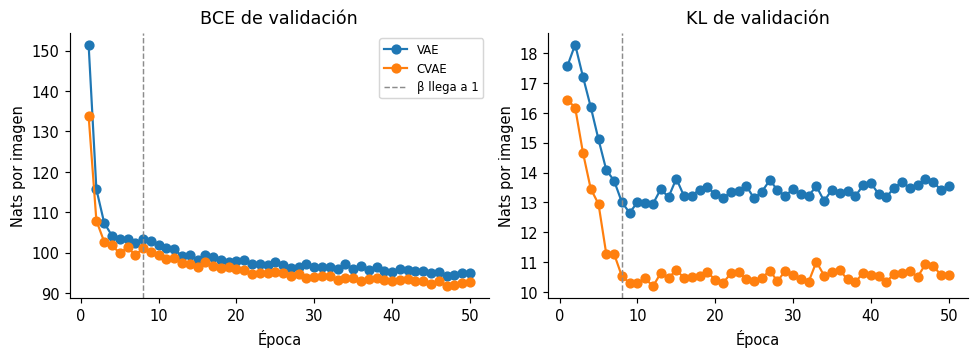

In [10]:
x_v_train, y_v_train = muestra_estratificada(x_train, y_train, 22000, SEMILLA + 2)
x_v_val, y_v_val = muestra_estratificada(x_val, y_val, 2000, SEMILLA + 2)

variacionales, historias_v, resumen_v = {}, {}, []
for nombre, condicionado in {"VAE": False, "CVAE": True}.items():
    keras.utils.set_random_seed(SEMILLA)
    entradas_train = entradas_variacionales(x_v_train, y_v_train if condicionado else None)
    entradas_val = entradas_variacionales(x_v_val, y_v_val if condicionado else None)
    datos_train = preparar_datos(entradas_train, mezclar=True)
    datos_val = preparar_datos(entradas_val)
    modelo = ModeloVariacional(condicionado)
    _ = modelo({k: v[:1] for k, v in entradas_train.items()})
    modelo.compile(optimizer=keras.optimizers.Adam(0.001, clipnorm=5.0))
    historia = modelo.fit(datos_train, validation_data=datos_val, epochs=EPOCAS_V,
                          callbacks=[SubirBeta()], shuffle=False, verbose=0).history
    variacionales[nombre] = modelo
    historias_v[nombre] = historia
    resumen_v.append({"Modelo": nombre,
                      "Parámetros entrenables": modelo.encoder.count_params() + modelo.decoder.count_params(),
                      "BCE de validación": historia["val_BCE"][-1],
                      "KL de validación": historia["val_KL"][-1]})

display(pd.DataFrame(resumen_v).round(3))

fig, axs = plt.subplots(1, 2, figsize=(9.2, 3.3), layout="constrained")
for nombre, historia in historias_v.items():
    epocas = np.arange(1, len(historia["val_BCE"]) + 1)
    for ax, metrica in zip(axs, ("BCE", "KL")):
        ax.plot(epocas, historia["val_" + metrica], marker="o", label=nombre)
for ax, metrica in zip(axs, ("BCE", "KL")):
    ax.axvline(8, linestyle="--", color="0.55", linewidth=1, label="β llega a 1")
    ax.set(xlabel="Época", ylabel="Nats por imagen", title=f"{metrica} de validación")
axs[0].legend(fontsize=8)
plt.show()

### 4.2 Generar desde el prior y controlar la clase

Cada columna de la grilla del CVAE mantiene fijo un vector $z$. Al recorrer sus filas cambia el dígito solicitado. Cada fila mantiene fija la clase y muestra cómo distintos $z$ pueden producir trazos diferentes. Mostramos $\sigma(\text{logits})$ como intensidad de gris, que corresponde a la media de la salida por píxel.

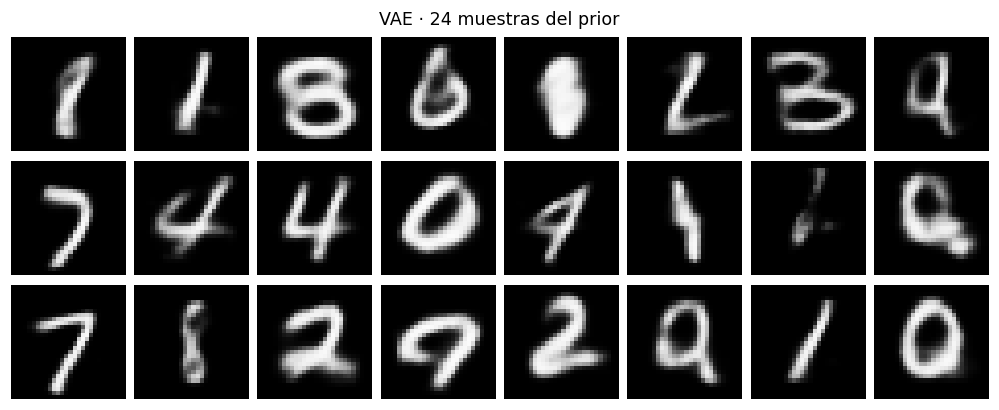

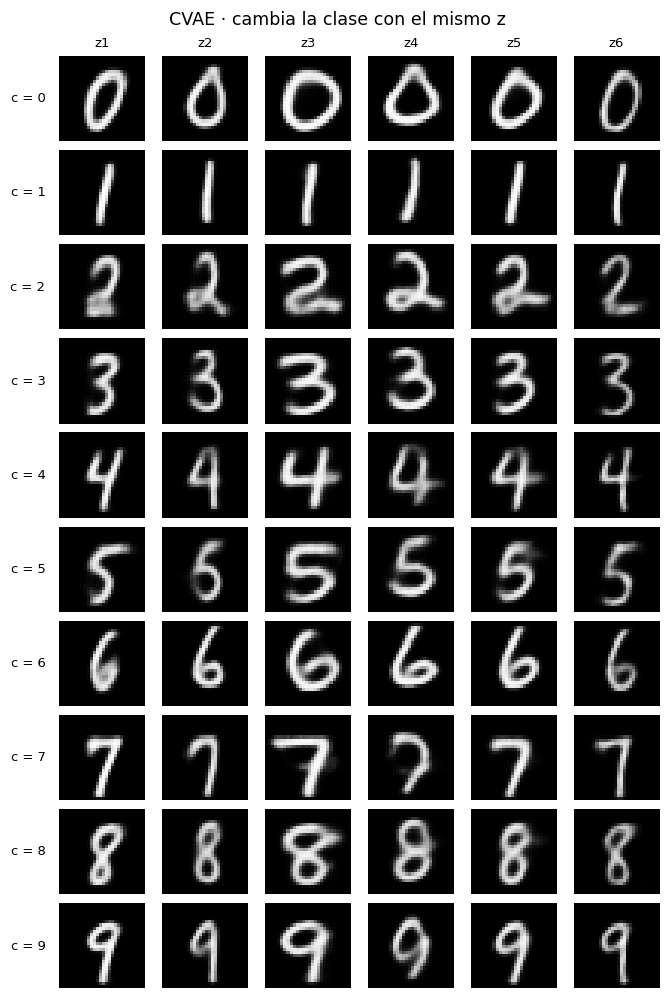

In [11]:
def generar(modelo, z, digitos=None):
    entradas = {"z": np.asarray(z, dtype=np.float32)}
    if digitos is not None:
        entradas["clase"] = np.eye(10, dtype=np.float32)[np.asarray(digitos)]
    logits = predecir(modelo.decoder, entradas)
    return tf.sigmoid(logits).numpy()

rng_generacion = np.random.default_rng(SEMILLA + 60)
z_demo = rng_generacion.standard_normal((24, LATENTE)).astype(np.float32)
digitos_vae = generar(variacionales["VAE"], z_demo)

fig, axs = plt.subplots(3, 8, figsize=(9.4, 3.8), layout="constrained")
for ax, imagen in zip(axs.flat, digitos_vae):
    mostrar_imagen(ax, imagen)
fig.suptitle("VAE · 24 muestras del prior")
plt.show()

n_columnas = 6
clases_demo = np.repeat(np.arange(10), n_columnas)
z_cond = np.tile(z_demo[:n_columnas], (10, 1))
digitos_cvae = generar(variacionales["CVAE"], z_cond, clases_demo)

fig, axs = plt.subplots(10, n_columnas, figsize=(6.3, 9.4), layout="constrained")
for i, (ax, imagen) in enumerate(zip(axs.flat, digitos_cvae)):
    mostrar_imagen(ax, imagen, f"z{i + 1}" if i < n_columnas else "")
for clase in range(10):
    axs[clase, 0].text(-0.16, 0.5, f"c = {clase}", transform=axs[clase, 0].transAxes,
                       va="center", ha="right", fontsize=9)
fig.suptitle("CVAE · cambia la clase con el mismo z")
plt.show()

### 4.3 Medir cuánto control aporta la condición

Entrenamos una **CNN evaluadora** solo con imágenes reales de entrenamiento y comprobamos su exactitud con la prueba oficial. Después la usamos para estimar qué clase parece tener cada imagen sintética. Generamos **120 imágenes por clase solicitada** y pasamos los mismos vectores latentes por ambos decoders. Para el VAE, las clases solicitadas sirven únicamente como referencia externa para calcular la coincidencia. Como las solicitudes están equilibradas y son independientes de $z$, esperamos una coincidencia cercana al 10 % para esa referencia.

Con la CNN evaluadora mediremos la **fidelidad a la clase**. Complementamos esa métrica con el heatmap para comprobar legibilidad y diversidad. Una CNN entrenada con datos reales también puede equivocarse con imágenes sintéticas.

In [12]:
entrada = keras.Input((28, 28, 1))
h = layers.Conv2D(16, 3, padding="same", activation="relu")(entrada)
h = layers.MaxPooling2D()(h)
h = layers.Conv2D(32, 3, padding="same", activation="relu")(h)
h = layers.MaxPooling2D()(h)
h = layers.Flatten()(h)
h = layers.Dense(48, activation="relu")(h)
evaluador = keras.Model(entrada, layers.Dense(10, activation="softmax")(h))
evaluador.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
datos_e_train = preparar_datos(x_v_train, y_v_train, mezclar=True)
datos_e_val = preparar_datos(x_v_val, y_v_val)
evaluador.fit(datos_e_train, validation_data=datos_e_val, epochs=10,
              shuffle=False, verbose=0)
reales = evaluador.evaluate(preparar_datos(x_test, y_test), return_dict=True, verbose=0)
print(f"Exactitud de la CNN evaluadora en prueba real: {reales['accuracy']:.2%}")

Exactitud de la CNN evaluadora en prueba real: 98.01%


,Modelo,Imágenes generadas,Coincidencia con la clase solicitada (%)
0,VAE,1200,8.50
1,CVAE,1200,98.17


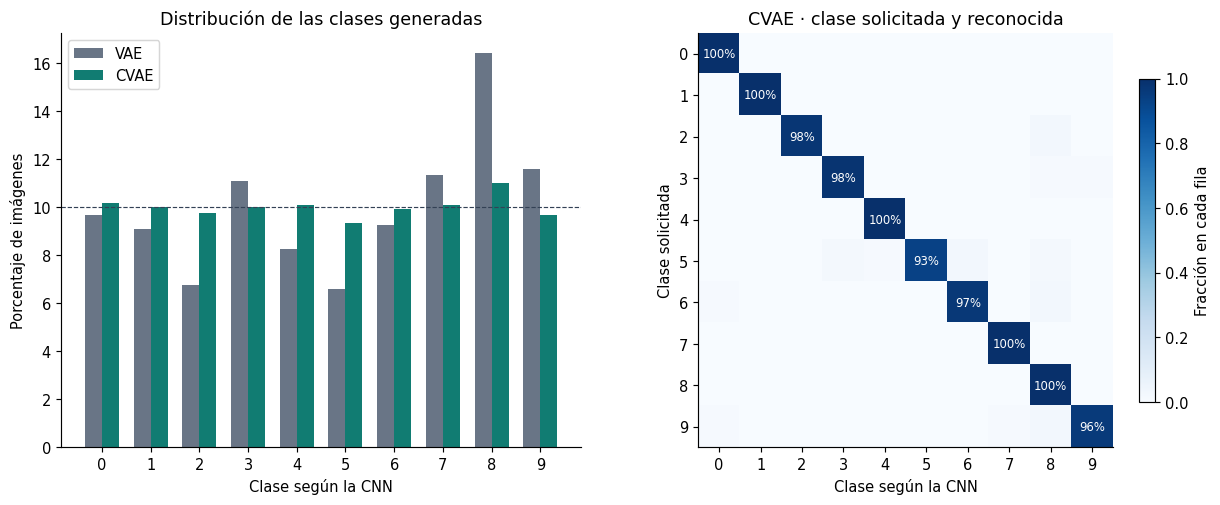

In [13]:
N_POR_CLASE = 120
solicitudes = np.repeat(np.arange(10), N_POR_CLASE)
z_muestreo = rng_generacion.standard_normal((len(solicitudes), LATENTE)).astype(np.float32)

muestras = {"VAE": generar(variacionales["VAE"], z_muestreo),
            "CVAE": generar(variacionales["CVAE"], z_muestreo, solicitudes)}
predicciones = {nombre: predecir(evaluador, x).argmax(axis=1)
                for nombre, x in muestras.items()}
tabla_generacion = pd.DataFrame([
    {"Modelo": nombre, "Imágenes generadas": len(pred),
     "Coincidencia con la clase solicitada (%)": 100 * np.mean(pred == solicitudes)}
    for nombre, pred in predicciones.items()
])
display(tabla_generacion.round(2))

cvas = confusion_matrix(solicitudes, predicciones["CVAE"],
                        labels=np.arange(10), normalize="true")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.7), layout="constrained")
ax = axs[0]
x = np.arange(10)
for j, (nombre, color) in enumerate({"VAE": "#697586", "CVAE": "#117c72"}.items()):
    proporcion = np.bincount(predicciones[nombre], minlength=10) / len(solicitudes)
    ax.bar(x + (j - 0.5)*0.35, 100*proporcion, width=0.35, color=color, label=nombre)
ax.axhline(10, color="#334155", linestyle="--", linewidth=0.8)
ax.set(title="Distribución de las clases generadas", xlabel="Clase según la CNN",
       ylabel="Porcentaje de imágenes", xticks=x)
ax.legend()

ax = axs[1]
mapa = ax.imshow(cvas, vmin=0, vmax=1, cmap="Blues")
ax.set(title="CVAE · clase solicitada y reconocida", xlabel="Clase según la CNN",
       ylabel="Clase solicitada", xticks=x, yticks=x)
for i, acierto in enumerate(cvas.diagonal()):
    ax.text(i, i, f"{acierto:.0%}", color="white" if acierto > 0.55 else "black",
            ha="center", va="center", fontsize=8)
fig.colorbar(mapa, ax=ax, shrink=0.78, label="Fracción en cada fila")
plt.show()

Las salidas del VAE pueden cubrir varias clases aun cuando la solicitud externa coincide con pocas. La diagonal de la matriz indica con qué frecuencia el CVAE produce una imagen que el evaluador reconoce como la clase pedida.

## 5. Experimentos para extender la práctica

1. **Compresión.** Cambia las dos dimensiones latentes por 8 en PCA, Kernel PCA y AE. Conserva el mismo conjunto de validación. Compara la reconstrucción y la exactitud de la sonda. Si quieres reutilizar la gráfica, proyecta los códigos a dos dimensiones para visualizarlos y calcula las métricas con las ocho coordenadas.
2. **Denoising.** Agrega oclusiones de 18 píxeles a la mezcla de entrenamiento. Evalúa si mejora en 22 píxeles y cuánto cambia el rendimiento con ruido leve. Procura cambiar un solo factor por corrida.
3. **Generación.** Compara latentes de 2, 8 y 16 dimensiones. Usa curvas de BCE y KL en validación, fidelidad a la clase y grillas generadas. Explica qué cambia entre la capacidad de reconstruir y la de producir dígitos solicitados. En otra corrida, fija el latente y cambia solo `ESCALA_CONDICION` de 4 a 1.

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de ChatGPT 6.2 Sol X-High para estructurar el contenido a partir de las diapositivas de la sesión y redactar el texto explicativo. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.